# Simple Grid World: Prediction with TD(0) and Linear Approximation

## Installation and Setup

In [2]:
# uncomment if needed
# %pip install gym-classics2

In [3]:
import numpy as np
np.set_printoptions(precision=2)

SEED = 42
rng = np.random.default_rng(SEED)

In [4]:
import gymnasium as gym
import gym_classics2

Helper functions

In [34]:
from matplotlib import pyplot as plt

def v_hat_grid(x, y, w):
    return np.dot(w, [1, x, y])

def show_value_function(w, title="Value Function"):
    x = np.linspace(0, env.dims[0]-1, 100)
    y = np.linspace(0, env.dims[1]-1, 100)
    X, Y = np.meshgrid(x, y)
    Z = np.array([v_hat_grid(x, y, w) for x, y in zip(np.ravel(X), np.ravel(Y))]).reshape(X.shape)

    plt.contourf(X, Y, Z, cmap='Reds')
    plt.title(title)
    plt.colorbar()
    plt.contour(X, Y, Z, colors='black') # Contour lines
    plt.show()

## Define the L-Maze

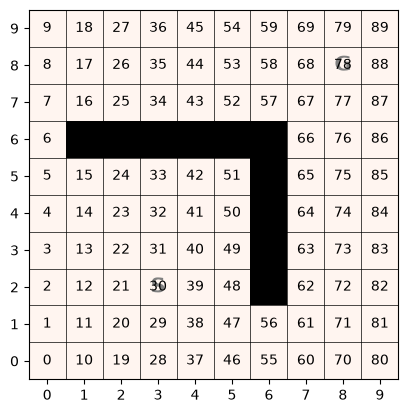

In [5]:
gym_env = gym.make('LMaze-v0', tabular=False)
env = gym_env.unwrapped
env.reset(seed=SEED)

env.image()

## Define a Policy To Evaluate

The manual policy leads to the goal

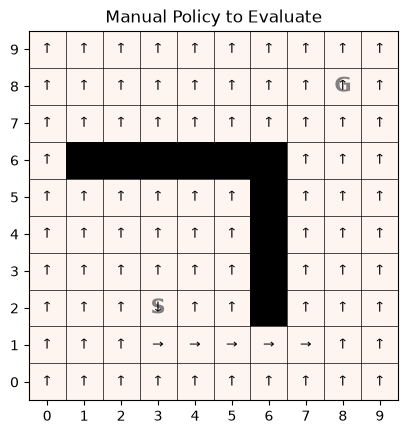

In [10]:
pol = np.full(len(env.states()), env.action2id('up'))
pol[[30]] = env.action2id('down')
pol[[29,38,47,56,61]] = env.action2id('right')
pol

env.image(policy = pol, title='Manual Policy to Evaluate')

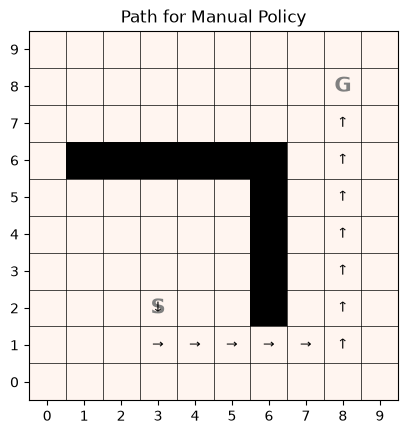

In [12]:
from gym_classics2.algorithms.monte_carlo_methods import sample_episode

path = sample_episode(env, policy=pol, max_len=100, rng=rng)
env.image(policy=pol, episode=path, title='Path for Manual Policy')

## Prediction with Linear State Features

In [24]:
from gym_classics2.algorithms.linear_approximation import semi_gradient_TD0, v_hat

In [13]:
def state_features(s, env):
    return np.concatenate([np.array([1]), np.array(s)])

In [22]:
w = semi_gradient_TD0(env, state_features, pol, n=100, alpha=0.1, gamma=0.9, max_episode_length=1000)

Semi-Gradient TD(0): 100%|██████████| 100/100 [00:00<00:00, 3731.69it/s]


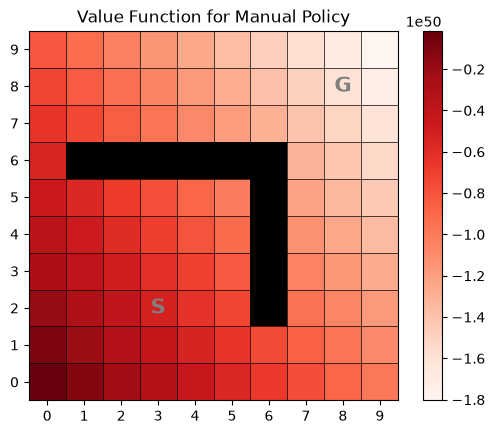

In [28]:
V = np.array([v_hat(env.id2state(s), w, env, state_features) for s in env.states()])
env.image(V, title = "Value Function for Manual Policy")

We can visualize the manually created value function using contours.

In [49]:
show_value_function(w, title = "Continuous Value Function for Manual Policy (Linear Features)")

ValueError: shapes (16,) and (3,) not aligned: 16 (dim 0) != 3 (dim 0)

## Prediction with Fourier Basis Function Features

In [46]:
from gym_classics2.algorithms.linear_approximation import transformation_fourier_basis

transform = transformation_fourier_basis([0, 0], [10, 10], order=3)

def state_features(state, env):
    return transform(state)

In [47]:
w = semi_gradient_TD0(env, state_features, pol, n=100, alpha=0.1, gamma=0.9, max_episode_length=1000)

Semi-Gradient TD(0): 100%|██████████| 100/100 [00:00<00:00, 1643.39it/s]


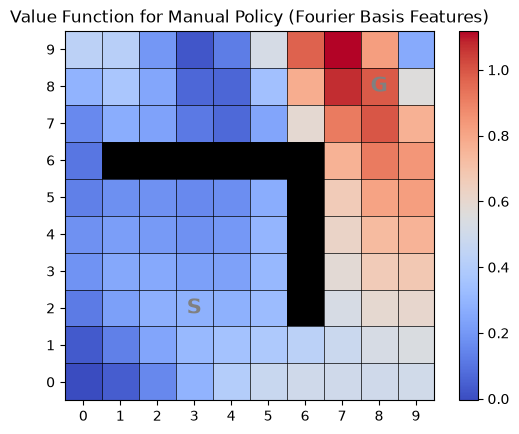

ValueError: shapes (16,) and (3,) not aligned: 16 (dim 0) != 3 (dim 0)

In [48]:
V = np.array([v_hat(env.id2state(s), w, env, state_features) for s in env.states()])
env.image(V, title = "Value Function for Manual Policy (Fourier Basis Features)")
show_value_function(w, title="Continuous Value Function for Manual Policy (Fourier Basis Features)")


&copy; 2025 [Michael Hahsler](https://michael.hahsler.net). 
This work is openly licensed under [Creative Commons Attribution-ShareAlike 4.0 International (CC BY-SA 4.0) License](https://creativecommons.org/licenses/by-sa/4.0/)

![CC BY-SA 4.0](https://licensebuttons.net/l/by-sa/3.0/88x31.png)